<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🗺️ 新旧课程对照 + deepagents 时间线（截至 2026-10-20）

**一句话定位**：`lca-deepagents` **不是**本课的新版，而是另一门课：本课教 harness 里的零件怎么手搓，新课教怎么**用** harness（deepagents 0.7）把一个真实产品搭出来、部署出去。
> 本笔记的版本信息来自 PyPI / GitHub release / LangChain 博客（见末尾来源），API 细节在本机 0.7.28 上核对。

</div>

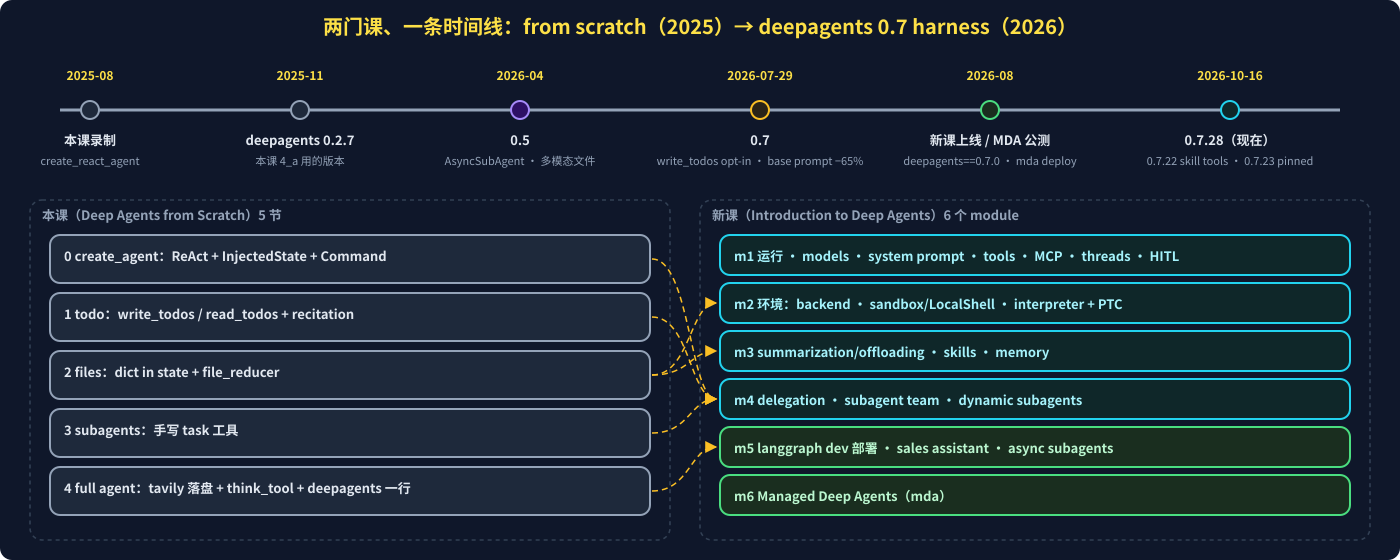

In [ ]:
from IPython.display import SVG
SVG(filename="assets/06_course_map.svg")

### 1️⃣ 两门课的关系

| | 本课 Deep Agents from Scratch | 新课 Foundation: Introduction to Deep Agents |
|---|---|---|
| 仓库 | `project-001-deep-agents`（5 个 notebook） | `lca-deepagents`（python + typescript 脚本，thinkific 课文） |
| 依赖 | langgraph 1.0.3 / langchain 1.0.7 / deepagents 0.2.7 | **deepagents==0.7.0**、langgraph 1.x、langchain-quickjs、langsmith[sandbox]、langgraph-cli |
| 做法 | `create_agent` + 自己写 state / tools | `create_deep_agent` + 参数 / middleware / 文本文件（AGENTS.md、SKILL.md） |
| 目标 | 理解 TODO / 文件 / 子 agent 三件武器的**内部** | 搭一个 Chinook 销售助理并 `langgraph dev` / `mda deploy` 上线 |
| 关键信息 | 「循环在 graph 里」「文件是注意力开关」「隔离只有一行」 | 「a little code + some text files」：行为大多由 AGENTS.md 与 skills 决定 |

本课内容**没有过时**（零件原理不变），过时的只是三处 API 细节：`write_todos` 默认带 → opt-in；`prompt` 键 → `system_prompt`；`files` 值 str → `FileData`。

### 2️⃣ 新课逐课表（python 版）

| 课 | 主题 | 核心 API | 对应本课 / 笔记 |
|---|---|---|---|
| m1.2 | 跑第一个 deep agent | `create_deep_agent(model=model)`、`.text` | 0_a · 笔记 01 |
| m1.3 | 换模型 | `init_chat_model("provider:model")`，`models.py` 一处改 | 0_a |
| m1.4 | system prompt + prompt caching | `system_prompt=`；0.7 无默认 base prompt；cache 断点 | 笔记 05 |
| m1.5 | tools | `@tool`；`tools=` 追加；内置 8 工具；并行 tool calls | 0_a · 笔记 01 |
| m1.6 | MCP | `MultiServerMCPClient({...}).get_tools()`；transport；allowlist；OAuth lab | 笔记 05 |
| m1.7 | messages / threads / checkpointers | `thread_id`、`MemorySaver()`、`get_state_history` time travel | foundation 笔记 15 |
| m1.8 | HITL | `interrupt_on`、`Command(resume={"decisions": [...]})`、approve/edit/reject/respond | 笔记 05 · foundation 笔记 14 |
| m2.1–2.3 | 环境：backend / sandbox / LocalShell | `StateBackend` `FilesystemBackend` `CompositeBackend` `FilesystemPermission` `LangSmithSandbox` `LocalShellBackend` | 2_a · 笔记 03 |
| m2.4 | interpreter | `CodeInterpreterMiddleware(ptc=[...])`（QuickJS，`eval` 工具，PTC） | 笔记 03 |
| m3.1 | summarization + offloading | `SummarizationMiddleware`（85%）、`/large_tool_results/`、`/conversation_history/` | 2_a · 笔记 03 |
| m3.2 | skills | `skills=["/skills"]`、SKILL.md frontmatter、渐进披露、`pinned_skills` | 笔记 05 |
| m3.3 | memory | `memory=["/memories/AGENTS.md"]`、`StoreBackend(namespace)`、`<agent_memory>` | 笔记 05 · foundation 笔记 10 |
| m4.1 | delegation | `TodoListMiddleware()`（planning）、`task`、context isolation、fork | 1_a 3_a · 笔记 02 04 |
| m4.2 | subagent team | 一个 `genre-researcher` 派 4 次、`permissions`、并行 | 3_a 4_a · 笔记 04 |
| m4.3 | dynamic subagents | interpreter 里 `task()` 循环 | 笔记 04 |
| m5.2 | 本地部署 | `langgraph dev`、`langgraph.json`、Agent Server API（assistants / threads / runs / store）、Studio | foundation 笔记 11 15 |
| m5.3 / 5.5 | sales assistant（+ sandbox 版） | AGENTS.md + 3 个 skills + MCP 邮箱 + 子 agent + HITL + interpreter | 4_a 的产品级版本 |
| m5.4 | async subagents | `AsyncSubAgent(graph_id, url)`，4 个 `*_async_task` 工具 | 笔记 04 |
| m6 | Managed Deep Agents | `mda init / dev / chat / deploy`，`define_deep_agent` | 笔记 06 ④ |

### 3️⃣ `deepagents` 时间线（PyPI 最新 0.7.28）

| 版本 / 时间 | 变化 |
|---|---|
| 0.2.7 · 2025-11 | 本课 4_a 使用；`write_todos` 默认带，子 agent 键 `prompt` |
| 0.5 · 2026-04 | **AsyncSubAgent**（远程 Agent Protocol 后台任务：start/check/update/cancel）、多模态文件读取（图 / 音 / 视频 / PDF）、Claude prompt caching 改进 |
| **0.7.0 · 2026-07-29** | `write_todos` 移出默认 harness（evals 无显著增益；`TodoListMiddleware` opt-in）；默认基础 token −65%（~6k → ~2k）；`BASE_AGENT_PROMPT` 弃用（0.9 删除）；同名 middleware 可覆盖默认；新增 NVIDIA Nemotron 3 Ultra profile |
| 0.7.2 · 2026-08-03 | 过滤模型不支持的多模态 block |
| 0.7.22 | **skill tools**：`metadata.include_tools`，读过 skill 才暴露工具 |
| 0.7.23 | **pinned skills**：`invoke({"pinned_skills": [...]})` |
| 0.7.2x | `mode="fork"`（实验）、`read_file` 的 `@@ lines @@` 状态头、`RubricMiddleware`、`ContextHubBackend`（LangSmith Hub 文件 backend）、async 子 agent 状态通知、NVIDIA OpenShell 沙盒 |
| 0.7.28 · 2026-10-16 | 本机验证版本 |

相关包：`langchain` 1.4.6 / `langgraph` 1.2.16（本机 scratch 环境）；`langchain-quickjs` 0.3.9；`managed-deepagents` 0.9.3。

### 4️⃣ 部署：从脚本到服务，再到托管

| 层 | 是什么 | 命令 / 要点 |
|---|---|---|
| 脚本 | `agent.invoke(...)` 打印 | 一次性任务 |
| **`langgraph dev`** | 本地 Agent Server：HTTP API + 持久化（threads）+ Store + 任务队列 + Studio | `langgraph.json` 的 `"graphs": {"agent": "./agent.py:graph"}`；`http://localhost:2024/docs` 自描述 API |
| Agent Server API | 所有 agent 同一套：Assistants · Threads · Thread Runs · Store · 无状态 Runs · Crons · 流式 · A2A · MCP | async 子 agent 的 `graph_id` 就是 `langgraph.json` 里的 key，`url` 就是服务器地址 |
| 生产 | LangSmith Deployment（Cloud / standalone / self-hosted） | 见 LangSmith Deployment 课 |
| **Managed Deep Agents（MDA）** | harness + 托管 runtime（Agent Server、沙盒、schedules、Slack 等 channels、Context Hub） | `uvx --from managed-deepagents mda init x` → `agent.py` + `instructions.md` + `skills/` + `sandbox/`；`mda dev` / `mda chat` 本地试；`mda deploy .` 上线，重跑即原地更新；`define_deep_agent(name=...)` 替代 `create_deep_agent`，`name` 兼作部署 id |

MDA 状态（2026-10）：博客 2026-08 宣布 public beta，文档页仍写 private beta、仅 LangSmith Cloud 美区、CLI-first；0.8（2026-09）加了内置 Parallel 搜索、connections（带身份调工具）、用户级记忆、Slack 文件传输。

### 5️⃣ 新课综合项目怎么把零件拼起来（Chinook 销售助理）

| 零件 | 在项目里 |
|---|---|
| 子 agent | `chinook-analyst`（数据库）、`inbox-manager`（邮件）、`quote-reviewer`、`genre-researcher`（并行写 newsletter） |
| Skills + AGENTS.md | 一本操作手册 + 每个任务一份 playbook（rfq-quote / weekly-newsletter / territory-report） |
| 文件系统 | 本地开发用 `FilesystemBackend`：skills、AGENTS.md、报价台账、newsletter.html |
| interpreter | 报价算术（行小计 + 折扣）用 `eval` 算，不让模型心算 |
| HITL | 两个有后果的动作：保存邮件草稿、新增客户 |
| MCP | 本地 mock 邮箱 MCP server |
| TODO（可选） | `TodoListMiddleware` 给多步 RFQ 流程排序 |

核心体会：**代码很少，行为大多写在文本里**（AGENTS.md / SKILL.md），改行为 = 改 markdown。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

### 复习时要注意的「过时点」速查

| 本课内容 | 2026-10 现状 |
|---|---|
| `create_react_agent` | `langchain.agents.create_agent`（本课 notebook 已改） |
| `Annotated[State, InjectedState]` | 仍可用；推荐 `runtime: ToolRuntime` |
| `create_deep_agent` 默认带 `write_todos` | 0.7 起 **opt-in**：`middleware=[TodoListMiddleware()]` |
| 子 agent dict 的 `prompt` 键 | `system_prompt` |
| `state["files"]` 值是 str | `FileData` dict；自定义工具写 str 会 `TypeError` |
| `read_file` 逐行行号 | `@@ lines a-b of n @@` 状态头 |
| `hwchase17/deepagents` | `langchain-ai/deepagents` |
| `MemorySaver` | 名字仍可用（别名 `InMemorySaver`） |

</div>

<div class="dark-cyan" style="background:#0f2729; color:#a5f3fc; padding:10px 24px; border-left:4px solid #22d3ee; border-radius:4px; width:97%;"><style>.dark-cyan strong{color:#fbbf24;}</style>

**来源**（2026-10-20 查阅）

- 新课：<https://academy.langchain.com/courses/foundation-introduction-to-deepagents> · 仓库 `langchain-ai/lca-deepagents`
- Deep Agents v0.7 博客（write_todos opt-in、−65% token）：<https://www.langchain.com/blog/deep-agents-v0-7>
- 0.7.22 release（skill tools）：<https://github.com/langchain-ai/deepagents/releases/tag/deepagents%3D%3D0.7.22> · PyPI：<https://pypi.org/project/deepagents/>
- Async subagents：<https://www.langchain.com/blog/running-subagents-in-the-background> · 文档：<https://docs.langchain.com/oss/python/deepagents/async-subagents>
- Dynamic subagents：<https://www.langchain.com/blog/introducing-dynamic-subagents-in-deep-agents>
- Managed Deep Agents 公测博客：<https://langchain.com/blog/managed-deep-agents-is-now-in-public-beta> · 文档：<https://docs.langchain.com/langsmith/managed-deep-agents-overview>
- Deep Agents 文档总览：<https://docs.langchain.com/oss/python/deepagents/overview>

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：本课 = 零件原理（不过时）；新课 = 用 0.7 harness 搭产品并部署。记住三处 API 变化（**TODO opt-in、`system_prompt` 键、`FileData`**）和新课六大新增（**MCP/HITL、sandbox/interpreter、summarization/skills/memory、subagent team/dynamic、部署/async、MDA**）。

</div>